<center><h1>Magdum_Seona_HW5</h1></center>
<br>
<br>

Name: Seona Magdum
<br>
Github Username: seo2003
<br>
USC ID: 6077378254

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.linear_model import LinearRegression, RidgeCV, Lasso, LassoCV
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error
)

from xgboost import XGBRegressor
from sklearn.preprocessing import LabelEncoder

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
data = pd.read_csv("../data/diagnosis.data", sep="\t", header=None, decimal=",", encoding="utf-16")

data.head()

,0,1,2,3,4,5,6,7
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### (b) Build a decision tree

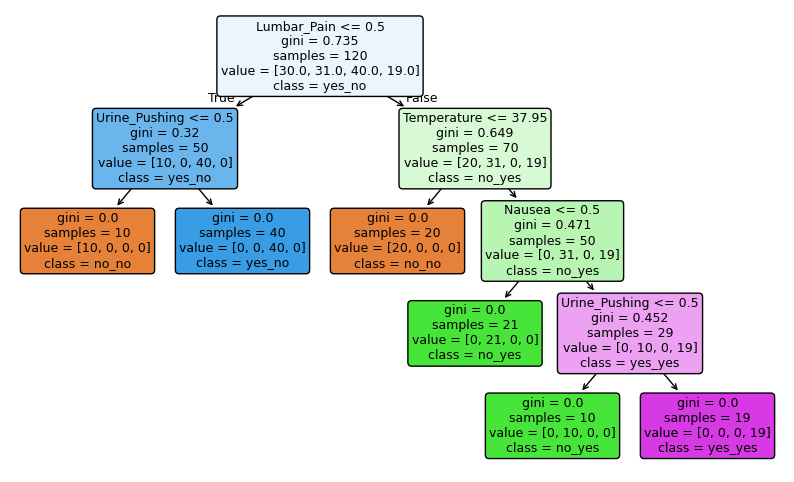

In [3]:
#column names
data.columns = [
    "Temperature", "Nausea", "Lumbar_Pain", "Urine_Pushing",
    "Micturition_Pains", "Burning_Urethra",
    "Inflammation", "Nephritis"
]

#features and labels
X = data.iloc[:, :6].copy()
y = data[["Inflammation", "Nephritis"]].copy()

#convert yes/no features to 1/0
for col in X.columns[1:]:
    X[col] = X[col].map({"yes": 1, "no": 0})

# Combine the two diagnosis labels
y_combined = y.astype(str).agg("_".join, axis=1)

#encode the combined labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y_combined)

#train on the entire dataset
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X, y_encoded)

#plot
plt.figure(figsize=(10, 6))
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=encoder.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.show()


### (c) Convert the decision rules

In [4]:
#convert into if then rules
rules = export_text(
    tree,
    feature_names=list(X.columns)
)

print(rules)

|--- Lumbar_Pain <= 0.50
|   |--- Urine_Pushing <= 0.50
|   |   |--- class: 0
|   |--- Urine_Pushing >  0.50
|   |   |--- class: 2
|--- Lumbar_Pain >  0.50
|   |--- Temperature <= 37.95
|   |   |--- class: 0
|   |--- Temperature >  37.95
|   |   |--- Nausea <= 0.50
|   |   |   |--- class: 1
|   |   |--- Nausea >  0.50
|   |   |   |--- Urine_Pushing <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- Urine_Pushing >  0.50
|   |   |   |   |--- class: 3



### (d)  minimal decision tree and a set of decision rules 

In [5]:
#find possible pruning values
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(
    X, y_encoded
)

ccp_alphas = path.ccp_alphas[:-1]

#compare
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

for alpha in ccp_alphas:
    model = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)

    scores = cross_val_score(model, X, y_encoded, cv=cv)

    model.fit(X, y_encoded)

    results.append({
        "alpha": alpha,
        "CV accuracy": scores.mean(),
        "leaves num": model.get_n_leaves(),
        "depth num": model.get_depth()
    })

results = pd.DataFrame(results)

#display
print(results.to_string(index=False))


   alpha  CV accuracy  leaves num  depth num
0.000000     0.991667           6          4
0.098167     0.858333           4          2
0.133333     0.758333           3          2
0.182000     0.666667           2          1


Alpha: 0.098167
leaves num: 4
depth num: 2
training accuracy: 0.8416666666666667


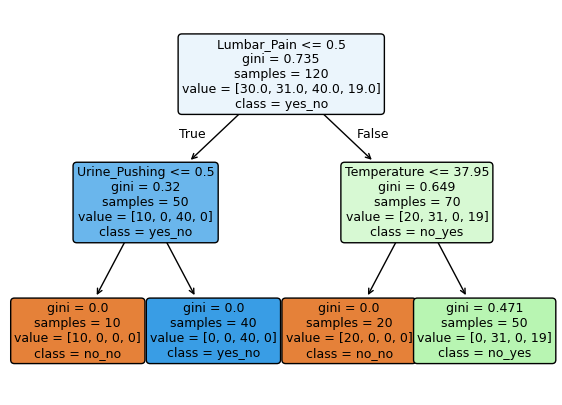

In [6]:
#train pruned tree
pruned_tree = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=0.098167
)

pruned_tree.fit(X, y_encoded)

print("Alpha:", 0.098167)
print("leaves num:", pruned_tree.get_n_leaves())
print("depth num:", pruned_tree.get_depth())
print("training accuracy:", pruned_tree.score(X, y_encoded))

#plot pruned tree
plt.figure(figsize=(7, 5))

plot_tree(
    pruned_tree,
    feature_names=list(X.columns),
    class_names=list(encoder.classes_),
    filled=True,
    rounded=True,
    fontsize=9
)

plt.show()

In [7]:
pruned_tree = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=0.098167
)

pruned_tree.fit(X, y_encoded)

print(export_text(pruned_tree, feature_names=list(X.columns)))

|--- Lumbar_Pain <= 0.50
|   |--- Urine_Pushing <= 0.50
|   |   |--- class: 0
|   |--- Urine_Pushing >  0.50
|   |   |--- class: 2
|--- Lumbar_Pain >  0.50
|   |--- Temperature <= 37.95
|   |   |--- class: 0
|   |--- Temperature >  37.95
|   |   |--- class: 1



## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [8]:
data = pd.read_csv(
    "../data/communities.data",
    header=None,
    na_values="?"
)

data.head()

,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [9]:
#first 1495 rows for training
train_data = data.iloc[:1495]
#remaining for testing
test_data = data.iloc[1495:]
print("Training set shape:", train_data.shape)
print("Test set shape:", test_data.shape)

Training set shape: (1495, 128)
Test set shape: (499, 128)


### (b) Missing values

In [10]:
#remove the 5 non-predictive columns
X_train = train_data.iloc[:, 5:-1]
y_train = train_data.iloc[:, -1]

X_test = test_data.iloc[:, 5:-1]
y_test = test_data.iloc[:, -1]

#replace missing values with the median (median imputation)
imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (1495, 122)
Test set: (499, 122)


### (c) Plot a correlation matrix

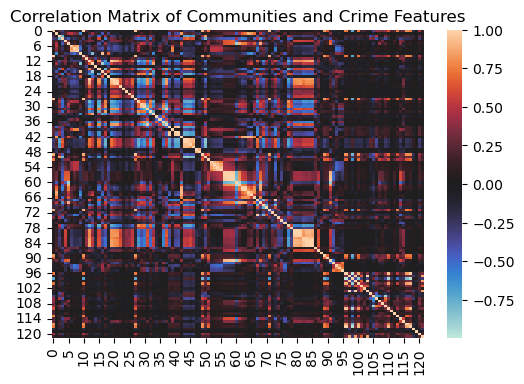

In [11]:
#calculate correlation matrix for the features
correlation_matrix = pd.DataFrame(X_train).corr()
#plot
plt.figure(figsize=(6, 4))
sns.heatmap(correlation_matrix, center=0)
plt.title("Correlation Matrix of Communities and Crime Features")
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [12]:
#convert the training features to a dataframe
features = pd.DataFrame(X_train)
#sample mean and sample sd
means = features.mean()
standard_deviations = features.std()
#cv
cv = standard_deviations / means

#show
cv_results = pd.DataFrame({
    "Mean": means,
    "SD ": standard_deviations,
    "CV": cv
})
print(cv_results)

         Mean       SD         CV
0    0.058167  0.130359  2.241105
1    0.461732  0.164284  0.355800
2    0.179839  0.256970  1.428885
3    0.752829  0.248594  0.330213
4    0.153712  0.208910  1.359100
..        ...       ...       ...
117  0.038074  0.062650  1.645508
118  0.752495  0.084304  0.112032
119  0.492308  0.164974  0.335104
120  0.093304  0.238201  2.552946
121  0.156515  0.063960  0.408650

[122 rows x 3 columns]


### (e) Scatter plots and box plots for highest CV features

In [13]:
n = math.floor(math.sqrt(128))
top_features = cv_results["CV"].abs().sort_values(ascending=False).head(n)

print(top_features)

# Get the selected feature values
X_df = pd.DataFrame(X_train)

108    5.527059
90     4.292923
89     3.470952
49     3.058964
51     2.926635
120    2.552946
27     2.342443
96     2.248042
0      2.241105
10     2.038461
71     1.968467
Name: CV, dtype: float64


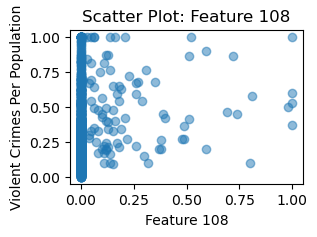

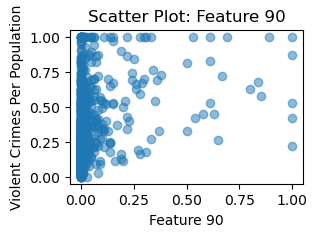

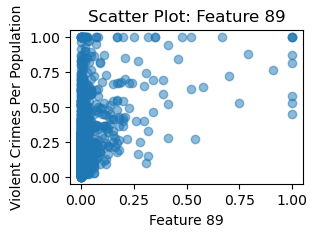

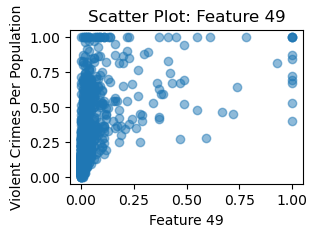

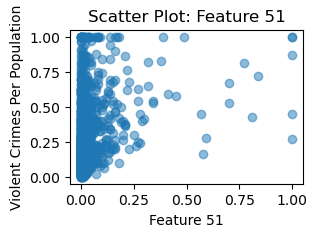

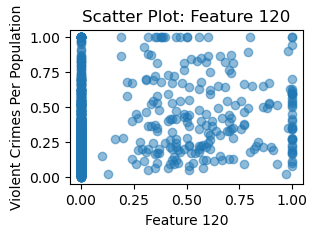

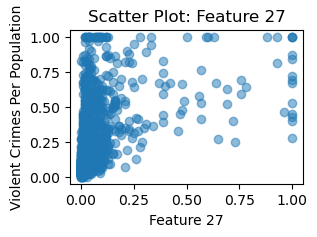

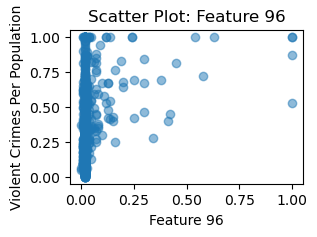

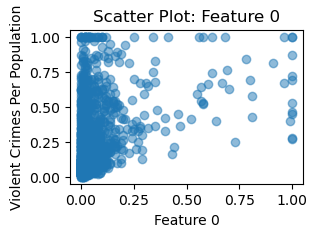

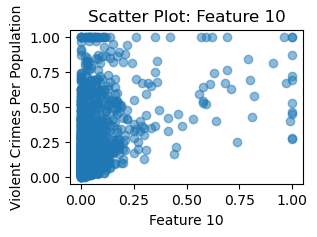

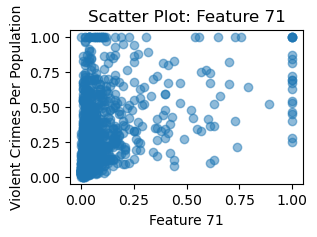

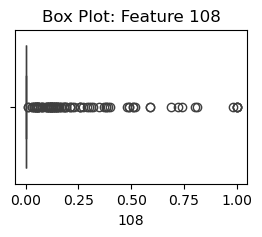

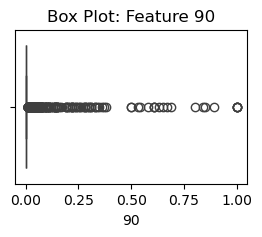

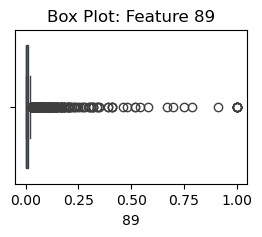

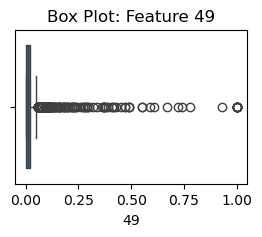

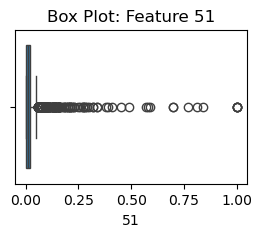

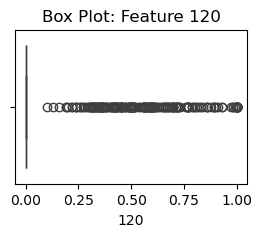

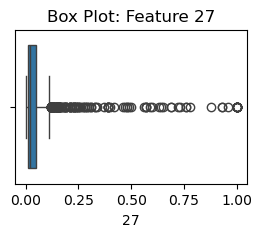

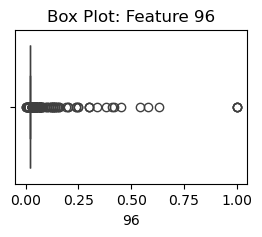

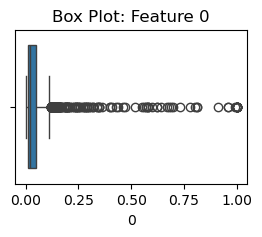

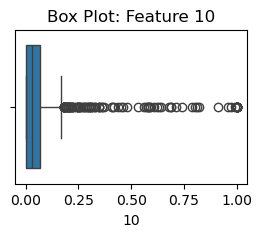

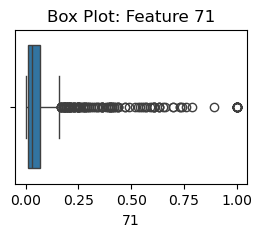

In [14]:
#scatter plots
for feature in top_features.index:
    plt.figure(figsize=(3, 2))
    plt.scatter(X_df[feature], y_train, alpha=0.5)
    plt.xlabel("Feature " + str(feature))
    plt.ylabel("Violent Crimes Per Population")
    plt.title("Scatter Plot: Feature " + str(feature))
    plt.show()

#box plots
for feature in top_features.index:
    plt.figure(figsize=(3, 2))
    sns.boxplot(x=X_df[feature])
    plt.title("Box Plot: Feature " + str(feature))
    plt.show()

No, you cannot draw conclusions about significance just by the scatter plots alone since they are only showing possible relationships between each feature and the crime rate. Box plots only show the features distribution. 

### (f) Fit a linear model

In [15]:
train_mask = y_train.notna()
test_mask = y_test.notna()
#least squares linear regression model
model = LinearRegression()
model.fit(X_train[train_mask], y_train[train_mask])
#predict the crime rate
y_pred = model.predict(X_test[test_mask])
#test error
mse = mean_squared_error(y_test[test_mask], y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test[test_mask], y_pred)

print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("Test MAE:", mae)

Test MSE: 0.017966215426067342
Test RMSE: 0.13403811184162265
Test MAE: 0.09626451953452168


### (g) Fit a ridge regression model

In [16]:
train_mask = y_train.notna()
test_mask = y_test.notna()
#different lambda values using 5 fold cross validation
alphas = np.logspace(-3, 5, 50)
ridge_model = RidgeCV(alphas=alphas, cv=5)
ridge_model.fit(X_train[train_mask], y_train[train_mask])
#predict
y_pred_ridge = ridge_model.predict(X_test[test_mask])
#mse
mse_ridge = mean_squared_error(y_test[test_mask], y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
print("Best lambda:", ridge_model.alpha_)
print("Test MSE:", mse_ridge)
print("Test RMSE:", rmse_ridge)

Best lambda: 2.6826957952797246
Test MSE: 0.01749797561792137
Test RMSE: 0.1322799138868837


### (h) Fit a LASSO model

In [17]:
#without standardizing 

#rows where the target is missing
train_mask = y_train.notna().to_numpy()
test_mask = y_test.notna().to_numpy()
X_train_clean = X_train[train_mask]
y_train_clean = y_train[train_mask].astype(float).to_numpy()
X_test_clean = X_test[test_mask]
y_test_clean = y_test[test_mask].astype(float).to_numpy()
#fit lasso w 5 fold
lasso_model = LassoCV(cv=5, max_iter=100000)
lasso_model.fit(X_train_clean, y_train_clean)
#predict and mse
y_pred_lasso = lasso_model.predict(X_test_clean)
mse_lasso = mean_squared_error(y_test_clean, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)

print("Best lambda:", lasso_model.alpha_)
print("Test MSE:", mse_lasso)
print("Test RMSE:", rmse_lasso)

#selected features (nonzero coefficients)
feature_names = [f"Column {i}" for i in range(6, 128)]
selected = np.where(lasso_model.coef_ != 0)[0]

selected_features_df = pd.DataFrame({
    "Selected Feature": [feature_names[i] for i in selected]
})
print("Number of selected features:", len(selected))
selected_features_df

Best lambda: 0.0001245408743775848
Test MSE: 0.017617760569778627
Test RMSE: 0.13273191240157217
Number of selected features: 74


,Selected Feature
0,Column 8
1,Column 10
2,Column 12
3,Column 13
4,Column 17
...,...
69,Column 120
70,Column 121
71,Column 122
72,Column 124


In [18]:
#lasso with standardizing 
#pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", Lasso(max_iter=100000))
])

param_grid = {
    "lasso__alpha": np.logspace(-4, 2, 60)
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)

grid.fit(X_train_clean, y_train_clean)

#predict and mse
y_pred_standardized = grid.predict(X_test_clean)
mse_standardized = mean_squared_error(
    y_test_clean, y_pred_standardized
)
rmse_standardized = np.sqrt(mse_standardized)

print("Best lambda:", grid.best_params_["lasso__alpha"])
print("Test MSE:", mse_standardized)
print("Test RMSE:", rmse_standardized)

# List selected features
standardized_coefs = grid.best_estimator_.named_steps["lasso"].coef_
selected_standardized = np.where(standardized_coefs != 0)[0]

selected_features_df = pd.DataFrame({
    "Selected Feature": [feature_names[i] for i in selected_standardized]
})

print("Number of selected features:", len(selected_standardized))
selected_features_df

Best lambda: 0.0008227241341700474
Test MSE: 0.017667887751550787
Test RMSE: 0.13292060694847427
Number of selected features: 72


,Selected Feature
0,Column 8
1,Column 10
2,Column 12
3,Column 13
4,Column 17
...,...
67,Column 120
68,Column 121
69,Column 122
70,Column 124


In [19]:
results = pd.DataFrame({
    "Metric": ["Test MSE", "Test RMSE"],
    "Original LASSO": [mse_lasso, rmse_lasso],
    "Standardized LASSO": [mse_standardized, rmse_standardized]
})

results

,Metric,Original LASSO,Standardized LASSO
0,Test MSE,0.017618,0.017668
1,Test RMSE,0.132732,0.132921


### (i) Fit a PCR model

In [20]:
#pipeline
pcr = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("linear", LinearRegression())
])
#different numbers of principal components
param_grid = {
    "pca__n_components": list(range(1, 123))
}
#choose the number of components using 5 fold cross validation
pcr_cv = GridSearchCV(
    pcr,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)
pcr_cv.fit(X_train_clean, y_train_clean)

# Predict and test errors
y_pred_pcr = pcr_cv.predict(X_test_clean)
mse_pcr = mean_squared_error(y_test_clean, y_pred_pcr)
rmse_pcr = np.sqrt(mse_pcr)

print("Best number of components:", pcr_cv.best_params_["pca__n_components"])
print("Best CV MSE:", -pcr_cv.best_score_)
print("Test MSE:", mse_pcr)
print("Test RMSE:", rmse_pcr)

Best number of components: 95
Best CV MSE: 0.019368968063156165
Test MSE: 0.018296345367709806
Test RMSE: 0.13526398400058237


### (j) Fit a boosting tree

In [21]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [22]:
#XGBoost regression model
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    n_jobs=1
)
#alpha values to test
param_grid = {
    "reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 100]
}

#alpha w 5 fold 
xgb_cv = GridSearchCV(
    xgb_model,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

#fit using the training data
xgb_cv.fit(X_train_clean, y_train_clean)

#predict and test errors
y_pred_xgb = xgb_cv.predict(X_test_clean)
mse_xgb = mean_squared_error(y_test_clean, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
print("Best alpha:", xgb_cv.best_params_["reg_alpha"])
print("Best CV MSE:", -xgb_cv.best_score_)
print("Test MSE:", mse_xgb)
print("Test RMSE:", rmse_xgb)

Best alpha: 0.01
Best CV MSE: 0.020094417308731197
Test MSE: 0.016024051815997434
Test RMSE: 0.12658614385467878
